# MAiDE-up reproduction - XLM-RoBERTa fine-tuning

CSCI 3052U Independent Activity (Hacker / Implementer role)

Paper: Ignat, Xu & Mihalcea (2025). *MAiDE-up: Multilingual Deception Detection of AI-generated Hotel Reviews*. Findings of NAACL 2025.

Dataset: authors' public repo, https://github.com/MichiganNLP/multilingual_reviews_deception

### Load and Inspect Dataset

In [ ]:
import pandas as pd
import torch
import random
import numpy as np
from transformers import set_seed

!git clone --depth 1 https://github.com/MichiganNLP/multilingual_reviews_deception.git
DATA_PATH = "multilingual_reviews_deception/data/all_data.csv"
df = pd.read_csv(DATA_PATH)
print(df.columns)

fatal: destination path 'multilingual_reviews_deception' already exists and is not an empty directory.
Index(['Unnamed: 0', 'Review_Language', 'City Name', 'Hotel Name',
       'Upside_Review', 'Downside_Review', 'Review_Score', 'Sentiment',
       'source', 'Prompt_Language', 'na_up_review', 'na_down_review'],
      dtype='object')


In [ ]:
# Display the first 5 rows of the dataset
display(df.head())

,Unnamed: 0,Review_Language,City Name,Hotel Name,Upside_Review,Downside_Review,Review_Score,Sentiment,source,Prompt_Language,na_up_review,na_down_review
0,0,Chinese,Ankara,迪万卡拉汉酒店,性价比超高的酒店，虽然价格比较贵，但是享受到的服务环境都还不错。,NaN,10.0,POS,0,NaN,False,True
1,1,Chinese,Ankara,迪万卡拉汉酒店,奥斯曼风格的建筑很有特色，房间装修精致，距离安卡拉城堡非常近，附近餐厅多，纪念品小商店多,不知道是不是因为夏季的原因，房间的空调不太给力，房间热；酒店员工会在窗外聊天，不考虑客人是不...,4.0,NEG,0,NaN,False,False
2,2,Chinese,Ankara,迪万卡拉汉酒店,非常喜歡酒店的環境氛圍，特別是通過地下通道到達博物館，這是一個驚喜（但入住時酒店服務人員并未...,酒店的空調令人傷心，第一天房間空調不起作用，次日上午出門時告知酒店經理，回來后依然沒有處理，...,5.0,NEG,0,NaN,False,False
3,3,Chinese,Ankara,安卡拉卡亚酒店,NaN,冷氣每隔5-15分鐘就會自動關閉，重新開啟有時候也要按三次才會開啟，飯店人員並沒有很積極地幫...,4.0,NEG,0,NaN,True,False
4,4,Chinese,Beijing,北京长城饭店(原北京喜来登长城饭店）,雖因為疫情影響加上老牌酒店旅客很少，但五星級的風骨猶存~這是寶藏好好傳承，比新酒店服務不到位強百倍,NaN,9.0,POS,0,NaN,False,True


## GPU check

In [ ]:


available = torch.cuda.is_available()
print("GPU available:", available)
if available:
    gpu_name = torch.cuda.get_device_name(0)
    print("GPU:", gpu_name)

GPU available: True
GPU: Tesla T4


## Fixed seed

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

print("Seed is set to: ", SEED)

Seed is set to:  42


## Train/test split (XLM-R)
Using the same cleaning method and train/test split as the TF-IDF baseline.

In [ ]:
from sklearn.model_selection import train_test_split

# Combine the upside and downside reviews
# Use the same cleaning as Part 1
df["text"] = df["Upside_Review"].fillna("") + " " + df["Downside_Review"].fillna("")
df["text"] = df["text"].str.strip()
df = df[df["text"] != ""]

# Select the columns we need
data = df[["text", "source", "Review_Language", "Sentiment"]]
data = data.rename(columns={"source": "label"})

# Same 80/20 split, stratified by label and language
groups = data.groupby(["label", "Review_Language"], dropna=False).ngroup()
train_df, test_df = train_test_split(
    data,
    test_size=0.2,
    random_state=SEED,
    stratify=groups
)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print(train_df["label"].value_counts(normalize=True))

assert len(train_df) == 15988 and len(test_df) == 3997

Training samples: 15988
Testing samples: 3997
label
1    0.500375
0    0.499625
Name: proportion, dtype: float64


## Same split: analysis
I used the same split so I can compare XLM-R with the TF-IDF models fairly. Both models will be tested on the same reviews, so the results won't change just because I used different test data. I also kept the same seed and stratified by the labels and languages, like I did in Part 1.

## XLM-R tokenization

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

# View one Chinese and one English review
chinese_text = train_df.loc[train_df["Review_Language"] == "Chinese", "text"].iloc[0]
english_text = train_df.loc[train_df["Review_Language"] == "English", "text"].iloc[0]

print("Chinese review:", chinese_text)
print("Chinese tokens:", tokenizer.tokenize(chinese_text))
print()
print("English review:", english_text)
print("English tokens:", tokenizer.tokenize(english_text))

Chinese review: 员工服务 设施陈旧，浴室有污迹， 隔音太差
Chinese tokens: ['▁', '员工', '服务', '▁', '设施', '陈', '旧', ',', '浴室', '有', '污', '迹', ',', '▁', '隔', '音', '太', '差']

English review: Staff were generally helpful
Room was comfortable and spacious
Good location: Close to the South Train Station Staff needed to be asked multiple times to fulfil requests
Breakfast is too expensive; Not good value for money
English tokens: ['▁Staff', '▁were', '▁generally', '▁helpful', '▁Room', '▁was', '▁comfortable', '▁and', '▁spa', 'cious', '▁Good', '▁location', ':', '▁Close', '▁to', '▁the', '▁South', '▁Train', '▁Station', '▁Staff', '▁needed', '▁to', '▁be', '▁asked', '▁multiple', '▁times', '▁to', '▁ful', 'fil', '▁request', 's', '▁Breakfast', '▁is', '▁too', '▁expensive', ';', '▁Not', '▁good', '▁value', '▁for', '▁money']


## Token lengths

In [ ]:
# Find how many tokens are in the training reviews
token_ids = tokenizer(train_df["text"].tolist(), truncation=False)["input_ids"]
lengths = [len(tokens) for tokens in token_ids]

print("Average length:", round(np.mean(lengths), 2))
print("Median length:", np.median(lengths))
print("95th percentile:", np.percentile(lengths, 95))
print("Longest review:", max(lengths))

# Choose the maximum length using the 95th percentile
p95 = np.percentile(lengths, 95)
MAX_LENGTH = 128 if p95 <= 128 else 256

print("Chosen max length:", MAX_LENGTH)
print("Reviews within the limit:", round(np.mean(np.array(lengths) <= MAX_LENGTH) * 100, 2), "%")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (599 > 512). Running this sequence through the model will result in indexing errors


Average length: 64.79
Median length: 54.0
95th percentile: 149.0
Longest review: 902
Chosen max length: 256
Reviews within the limit: 99.04 %


## Tokenized datasets

In [ ]:
from datasets import Dataset

# Convert the dataframes to Hugging Face datasets
train_dataset = Dataset.from_pandas(train_df[["text", "label"]], preserve_index=False)
test_dataset = Dataset.from_pandas(test_df[["text", "label"]], preserve_index=False)

# Tokenize the reviews
def tokenize_reviews(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

train_dataset = train_dataset.map(tokenize_reviews, batched=True)
test_dataset = test_dataset.map(tokenize_reviews, batched=True)

train_dataset = train_dataset.rename_column("label", "labels")
test_dataset = test_dataset.rename_column("label", "labels")

print(train_dataset)
print(test_dataset)


Map:   0%|          | 0/15988 [00:00<?, ? examples/s]

Map:   0%|          | 0/3997 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'labels', 'input_ids', 'attention_mask'],
    num_rows: 15988
})
Dataset({
    features: ['text', 'labels', 'input_ids', 'attention_mask'],
    num_rows: 3997
})


## Tokenization: analysis

XLM-R can break Chinese reviews into meaningful tokens like '员工', '服务' and '浴室' even if Chinese generally has no spaces between words. This is connected to my results in Part 1 where Chinese accuracy increased from 80.35% to 90.93% when I used character-level TF-IDF instead of word-level TF-IDF. XLM-R also breaks words into smaller pieces, like "spa" and "cious" which makes it better at handling less common words for English. I set a maximum length of 256 tokens, so the longest review with 902 tokens will be cut off, but this only applies to about 1% of the reviews.

## XLM-R sanity run

In [ ]:
from transformers import AutoModelForSequenceClassification

model_name = "xlm-roberta-base"

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Accuracy and F1

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = logits.argmax(axis=1)
    accuracy = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "f1": f1
    }

## Train on 1k reviews

In [ ]:
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding

# Use 1,000 reviews for training and 200 others for evaluation
shuffled_dataset = train_dataset.shuffle(seed=SEED)
train_indices = range(1000)
eval_indices = range(1000, 1200)
sanity_train = shuffled_dataset.select(train_indices)
sanity_eval = shuffled_dataset.select(eval_indices)

training_args = TrainingArguments(
    output_dir="./xlmr_sanity",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=1,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=SEED
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=sanity_train,
    eval_dataset=sanity_eval,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.467538,0.825000,0.841629


TrainOutput(global_step=125, training_loss=0.48377328491210936, metrics={'train_runtime': 19.136, 'train_samples_per_second': 52.258, 'train_steps_per_second': 6.532, 'total_flos': 73971206548320.0, 'train_loss': 0.48377328491210936, 'epoch': 1.0})

In [ ]:
metrics = trainer.evaluate()

accuracy = metrics["eval_accuracy"]
f1 = metrics["eval_f1"]
print(f"Sanity Accuracy: {accuracy}")
print(f"Sanity F1: {f1}")

Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.467538,1,0.825000,0.841629


Sanity Accuracy: 0.825
Sanity F1: 0.8416289592760181


## Sanity run: analysis

First, I trained XLM-R on 1,000 reviews for 1 epoch with the learning rate of 2e-5 and batch size of 8 as stated in the paper. Training took about 17 seconds.

I ran the model on 200 different reviews from the training split and got 82.0% accuracy and 83.9% F1. This is much greater than the chance level of 50 %, indicating that the model is learning even with a small data set. However, this is lower than the paper's 94.8% accuracy, which is expected since I used fewer reviews and only one epoch.

The training loss is shown as "No log" because this run only has 125 steps, whereas the Trainer logs every 500 steps by default. This is not an error. I will set logging_steps=100 to track for the full training.

## Validation split

In [ ]:
# split into training data
group_labels = train_df.groupby(
    ["label", "Review_Language"],
    dropna=False
).ngroup()

indices = np.arange(len(train_dataset))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.1,
    random_state=SEED,
    stratify=group_labels
)

full_train = train_dataset.select(list(train_idx))
full_val = train_dataset.select(list(val_idx))

print("Training reviews:", len(full_train))
print("Validation reviews:", len(full_val))
print("Testing reviews:", len(test_dataset))

Training reviews: 14389
Validation reviews: 1599
Testing reviews: 3997


## Full XLM-R training

In [ ]:
model_name = "xlm-roberta-base"

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
training_args = TrainingArguments(
    output_dir="./xlmr_full",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=5,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    save_total_limit=1,
    logging_steps=100,
    report_to="none",
    seed=SEED
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=full_train,
    eval_dataset=full_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.216233,0.162319,0.958099,0.958359
2,0.142222,0.292968,0.939337,0.941881
3,0.064652,0.280955,0.958724,0.959854
4,0.032299,0.265528,0.962477,0.962825
5,0.011695,0.405424,0.948093,0.950030


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=8995, training_loss=0.10155414814515668, metrics={'train_runtime': 1462.4421, 'train_samples_per_second': 49.195, 'train_steps_per_second': 6.151, 'total_flos': 5161563142417500.0, 'train_loss': 0.10155414814515668, 'epoch': 5.0})

## XLM-R test results

In [ ]:
# Evaluate the best model on the test set
results = trainer.evaluate(test_dataset)

# Calculate metrics using the keys returned by compute_metrics ('accuracy' and 'f1')
accuracy = round(results["eval_accuracy"] * 100, 2)
f1 = round(results["eval_f1"] * 100, 2)

print(f"XLM-R Accuracy: {accuracy}%")
print(f"XLM-R F1: {f1}%")

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.011695,0.190740,5,0.973230,0.973469


XLM-R Accuracy: 97.32%
XLM-R F1: 97.35%


## Compare results

In [ ]:
comparison_xlmr = pd.DataFrame(
    {
        "Metric": ["Accuracy", "F1"],
        "Paper (%)": [94.8, 94.9],
        "My XLM-R (%)": [accuracy, f1],
        "Difference (pp)": [round(accuracy - 94.8, 2), round(f1 - 94.9 , 2)]
    }
)

display(comparison_xlmr
)

,Metric,Paper (%),My XLM-R (%),Difference (pp)
0,Accuracy,94.8,97.32,2.52
1,F1,94.9,97.35,2.45


## Training Loss

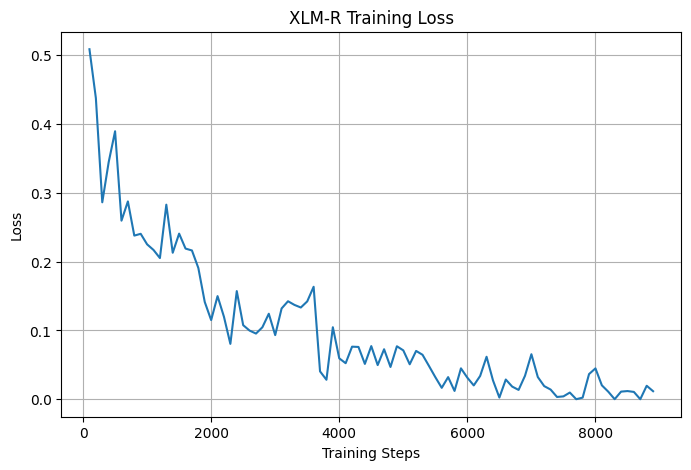

In [ ]:
import matplotlib.pyplot as plt

# Get the recorded training loss
loss_logs = []

for log in trainer.state.log_history:
    if "loss" in log:
        loss_logs.append(log)

steps = []
losses = []

for log in loss_logs:
    steps.append(log["step"])
    losses.append(log["loss"])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(steps, losses)
ax.set_title("XLM-R Training Loss")
ax.set_xlabel("Training Steps")
ax.set_ylabel("Loss")
ax.grid(True)

plt.show()

In [ ]:
print(trainer.state.best_model_checkpoint)

./xlmr_full/checkpoint-7196


## XLM-R results: analysis

**1. Training performance and overfitting**

XLM-R reached 97.32% accuracy and 97.35 F1 on the test set, 2.52 points above the paper’s 94.8%. However, the results show signs of overfitting after epoch 4.  Training loss took a continuous decrease, and dropped all the way to 0.012 by epoch 5.  Validation loss went the other way though from 0.27 up to 0.41 and accuracy slipped from 96.2% down to 94.8%.

This could mean the model was learning the training data too closely and losing some ability to handle unseen reviews. Meaning more epochs did not really help after that point. Picking the best checkpoint from validation performance looks better than using the final epoch.

**2. Training loss curve**

The training loss demonstrates a downward trend suggesting learning was actually happening. Sharp drops showed up around steps 1800 and 3600 which line up with epoch boundaries, about 1,799 steps per epoch.

Each epoch had roughly 1799 steps so it may be starting a new pass through the data played a part in this result. Individual batches can still jump around though so the epoch boundaries alone do not fully explain the sudden changes.

**3. Comparison with the paper and reproducibility**

My model run gained a higher performance than the paper's result. This doesn't mean I used a better implementation as my experimental settings were different.

I went with an 80/20 split, stratified by label and language and a fixed random seed of 42. I also set max length to 256 after checking the token lengths (the 95th percentile was 149 tokens), which the paper does not report. The authors’ notebook stratifies the split by label only. Difference in library versions might matter as well.

Not to mention, I only used a single random seed (42). It would be good to run the model on multiple seeds to know whether the better performance is consistent or partly due to the specific data split and randomness of training.

In summary, the results indicate that I managed to replicate the approach and perform well. However, it is difficult to compare my results directly with the paper due to the differences in the experimental settings.

The evaluated model is the best checkpoint, checkpoint-7196 (epoch 4). I ran the full training twice with the same code and seed. The first run reached 97.35% with the best checkpoint at epoch 3, and the second reached 97.32% with the best checkpoint at epoch 4. This is GPU non-determinism: with fp16, calculations are not added up in exactly the same order every time. Setting full_determinism=True in TrainingArguments would fix this, but makes training slower.

## XLM-R accuracy by language

In [ ]:
# Get predictions from the full XLM-R model
predictions = trainer.predict(test_dataset)

xlmr_predictions = np.argmax(
    predictions.predictions,
    axis=1
)

# Calculate accuracy by language
xlmr_test_df = test_df.copy()
xlmr_test_df["pred_xlmr"] = xlmr_predictions

xlmr_test_df["correct"] = (
    xlmr_test_df["pred_xlmr"]
    == xlmr_test_df["label"]
)

xlmr_language_accuracy = xlmr_test_df.groupby(
    "Review_Language"
)["correct"].mean()

xlmr_language_accuracy = (
    xlmr_language_accuracy * 100
)

xlmr_language_accuracy = (
    xlmr_language_accuracy.sort_values()
)

xlmr_language_accuracy

,correct
Review_Language,
Romanian,96.250000
Italian,96.500000
Turkish,97.000000
German,97.250000
Spanish,97.250000
Korean,97.250000
Chinese,97.732997
English,97.750000
French,98.000000


## Compare XLM-R with Part 1

In [ ]:
# Word-level Random Forest results, copied from notebook 01 outputs

language_accuracy = pd.Series({
    "Chinese": 80.352645,
    "English": 90.25,
    "French": 93.50,
    "German": 90.25,
    "Italian": 94.00,
    "Korean": 89.75,
    "Romanian": 91.75,
    "Russian": 93.25,
    "Spanish": 94.50,
    "Turkish": 93.25
})

# Saved Character-level Random Forest results
char_language_accuracy = pd.Series({
    "Chinese": 90.93199,
    "English": 87.00,
    "French": 90.75,
    "German": 88.75,
    "Italian": 92.25,
    "Korean": 92.25,
    "Romanian": 90.00,
    "Russian": 93.75,
    "Spanish": 92.75,
    "Turkish": 94.25
})

# Compare all three models
language_comparison = pd.DataFrame({
    "Word RF (%)": language_accuracy,
    "Character RF (%)": char_language_accuracy,
    "XLM-R (%)": xlmr_language_accuracy
})

display(language_comparison.round(2))

,Word RF (%),Character RF (%),XLM-R (%)
Chinese,80.35,90.93,97.73
English,90.25,87.00,97.75
French,93.50,90.75,98.00
German,90.25,88.75,97.25
Italian,94.00,92.25,96.50
Korean,89.75,92.25,97.25
Romanian,91.75,90.00,96.25
Russian,93.25,93.75,98.25
Spanish,94.50,92.75,97.25
Turkish,93.25,94.25,97.00


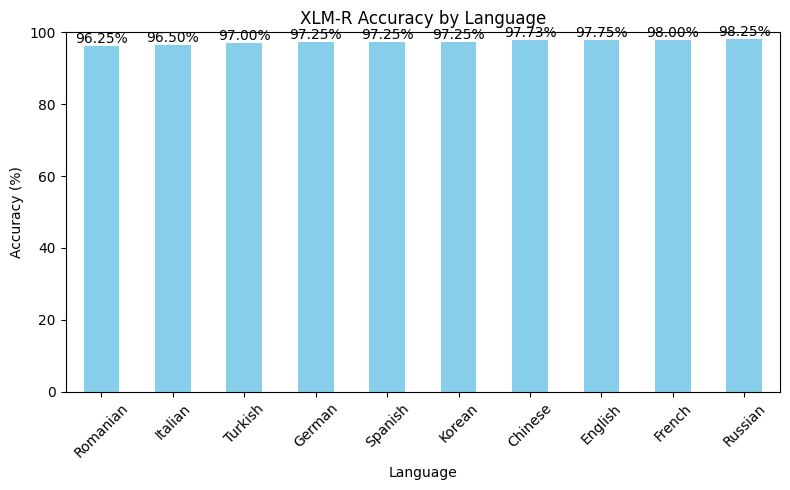

In [ ]:
# XLM-R accuracy by language
plt.figure(figsize=(8, 5))

ax = xlmr_language_accuracy.plot(
    kind="bar",
    color="skyblue"
)

bars = ax.containers[0]
ax.bar_label(
    bars,
    fmt="%.2f%%"
)

plt.title("XLM-R Accuracy by Language")
plt.ylabel("Accuracy (%)")
plt.xlabel("Language")
plt.ylim(0, 100)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## XLM-R accuracy by language: analysis

I tested my Word and Character Random Forest models from Part 1 against the full XLM-R model on the same test set.

XLM-R performed better on all 10 languages with accuracy ranging between 96.25% and 98.25%. The most accurate was Russian, with 98.25% accuracy, and the least was Romanian, with 96.25%. This differs from Figure 3a in the paper, where Korean and English were the hardest languages and German and Romanian the easiest. However, each language has only about 400 test reviews, so one review is worth 0.25 percentage points. The whole spread from 96.25% to 98.25% is about 8 reviews, so the ranking between languages is mostly noise.

The biggest improvement was in Chinese where accuracy improved from 80.35% with Word RF and 90.93% with Character RF to 97.73% with XLM-R. This is consistent with my earlier findings that character-level features are more effective for Chinese than word-level features. XLM-R further improves by using subword tokenization and multilingual pretrained representations.

Overall, XLM-R showed more consistent performance across languages compared to Random Forest models.

## Few-shot sampling

In [ ]:
# Use only the training reviews (validation reviews excluded).
# Sample 10 real and 10 fake reviews per language
fewshot_pool = train_df.iloc[train_idx].copy()
fewshot_pool.reset_index(drop=True, inplace=True)

fewshot_df = fewshot_pool.groupby(
    ["label", "Review_Language"]
).sample(10, random_state=SEED)

print("Few-shot samples:", len(fewshot_df))
print(fewshot_df["label"].value_counts())

# Check samples per language and label
sample_counts = fewshot_df.groupby(
    ["Review_Language", "label"] ).size()

print(sample_counts)
# Select the same reviews from the tokenized training dataset
indices = list(fewshot_df.index)
fewshot_train = full_train.select(indices)

print("Few-shot training samples:", len(fewshot_train))

## Few-shot XLM-R training

In [ ]:
# Move full model to CPU to free GPU memory
model = trainer.model
model.to("cpu")
torch.cuda.empty_cache()

# Load a fresh XLM-R model
model_name = "xlm-roberta-base"
fewshot_model = (
    AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2
    )
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# Few-shot training settings
fewshot_args = TrainingArguments(
    output_dir="./xlmr_fewshot",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=5,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    save_total_limit=1,
    logging_steps=10,
    report_to="none",
    seed=SEED
)

In [ ]:
# Train on 200 reviews
fewshot_trainer = Trainer(
    model=fewshot_model,
    args=fewshot_args,
    train_dataset=fewshot_train,
    eval_dataset=full_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

fewshot_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.716202,0.653718,0.624765,0.724265
2,0.611165,0.552394,0.782364,0.809836
3,0.538362,0.460188,0.870544,0.870867
4,0.473118,0.488717,0.786116,0.820755
5,0.385889,0.387286,0.873046,0.880518


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=125, training_loss=0.5557568664550782, metrics={'train_runtime': 1057.3984, 'train_samples_per_second': 0.946, 'train_steps_per_second': 0.118, 'total_flos': 67397541274560.0, 'train_loss': 0.5557568664550782, 'epoch': 5.0})

## Few-shot results

In [ ]:
# Evaluate on the same test set
fewshot_results = fewshot_trainer.evaluate(test_dataset)

print("Few-shot Accuracy:", round(fewshot_results["eval_accuracy"] * 100, 2), "%")
print("Few-shot F1:", round(fewshot_results["eval_f1"] * 100, 2), "%")

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.385889,0.393252,5,0.872404,0.879887


Few-shot Accuracy: 87.24 %
Few-shot F1: 87.99 %


In [ ]:
fewshot_accuracy = round(
    fewshot_results["eval_accuracy"] * 100,
    2
)

fewshot_comparison = pd.DataFrame(
    {
        "Model": [
            "Paper XLM-R Few-shot",
            "My XLM-R Few-shot"
        ],
        "Accuracy (%)": [
            76.6,
            fewshot_accuracy
        ]
    }
)

display(fewshot_comparison)

,Model,Accuracy (%)
0,Paper XLM-R Few-shot,76.60
1,My XLM-R Few-shot,87.24


## Few-shot: analysis

I re-trained a new XLM-R model but with only 200 reviews, 10 real and 10 fake for each language. The training settings remained the same from the full model to see the training performance with limited data.

My few-shot model gained a 87.24% accuracy and 87.99% F1, compared to the paper at 76.6%. This was 10.64 percentage points higher, which shows XLM-R still performs well with a small amount of training data.

Last thing to note, the paper evaluated its own few-shot model with 19,800 reviews. I used my test set of 3,997 reviews. Therefore, we can't compare results directly as test sets aren't the same. Also, I chose the best epoch using 1,599 validation reviews, which is a lot of labeled data for a few-shot setting and may partly explain the higher accuracy. Unlike the full run, the best few-shot epoch was the last one (epoch 5), which suggests it had not finished learning.
